In [1]:
%pip install ultralytics==8.4.192


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 26.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics] [ultralytics]
Note: you may need to restart the kernel to use updated packages.


In [35]:

from pathlib import Path

baseline_path = Path(
    "/kaggle/working/pascalvision/runs/"
    "baseline_5_epochs_kaggle/weights/best.pt"
)

model_10_path = Path(
    "/kaggle/working/pascalvision/runs/"
    "experiment_10_epochs_kaggle/weights/best.pt"
)

dataset_yaml = Path("/kaggle/working/VOC.yaml")
sample_image = Path(
    "/kaggle/working/datasets/VOC/images/test2007/000003.jpg"
)

checks = {
    "5-epoch checkpoint": baseline_path,
    "10-epoch checkpoint": model_10_path,
    "Dataset YAML": dataset_yaml,
    "Sample validation image": sample_image,
}

for name, path in checks.items():
    status = "OK" if path.exists() else "MISSING"
    print(f"{status}: {name} -> {path}")

missing = [name for name, path in checks.items() if not path.exists()]

if missing:
    raise FileNotFoundError(
        "Fix these missing files before continuing: " + ", ".join(missing)
    )

print("\nAll required files were found!")


OK: 5-epoch checkpoint -> /kaggle/working/pascalvision/runs/baseline_5_epochs_kaggle/weights/best.pt
OK: 10-epoch checkpoint -> /kaggle/working/pascalvision/runs/experiment_10_epochs_kaggle/weights/best.pt
OK: Dataset YAML -> /kaggle/working/VOC.yaml
OK: Sample validation image -> /kaggle/working/datasets/VOC/images/test2007/000003.jpg

All required files were found!


In [36]:

from pathlib import Path

yaml_path = Path("/kaggle/working/VOC.yaml")

yaml_content = """path: /kaggle/working/datasets/VOC
train:
  - images/train2007
  - images/train2012
val: images/test2007
names:
  0: aeroplane
  1: bicycle
  2: bird
  3: boat
  4: bottle
  5: bus
  6: car
  7: cat
  8: chair
  9: cow
  10: diningtable
  11: dog
  12: horse
  13: motorbike
  14: person
  15: pottedplant
  16: sheep
  17: sofa
  18: train
  19: tvmonitor
"""

yaml_path.write_text(yaml_content)
print("Created:", yaml_path)
print("File exists:", yaml_path.exists())


Created: /kaggle/working/VOC.yaml
File exists: True


In [37]:
import torch
import ultralytics

print("Ultralytics:", ultralytics.__version__)
print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Ultralytics: 8.4.192
PyTorch: 2.11.0+cu128
GPU available: True
GPU: Tesla T4


In [38]:

from ultralytics import YOLO

# Load a pretrained YOLO object-detection model
model = YOLO("yolo26n.pt")

# Fine-tune it on the Pascal VOC detection dataset
results = model.train(
    data="VOC.yaml",
    epochs=5,
    imgsz=640,
    batch=16,
    device=0,
    workers=2,
    project="/kaggle/working/pascalvision/runs",
    name="baseline",
    exist_ok=True
)


Ultralytics 8.4.192 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=VOC.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=baseline, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, overlap_ma

In [39]:
from ultralytics import YOLO
from pathlib import Path

model_path = Path(
    "/kaggle/working/pascalvision/runs/"
    "baseline_5_epochs_kaggle/weights/best.pt"
)

model = YOLO(str(model_path))
print("Model loaded successfully!")
print("Model task:", model.task)

Model loaded successfully!
Model task: detect


Model exists: True
Validation folder exists: True
Images found: 3

0: 640x640 1 dog, 1 person, 5.7ms
1: 640x640 1 train, 5.7ms
2: 640x640 (no detections), 5.7ms
Speed: 1.5ms preprocess, 5.7ms inference, 0.9ms postprocess per image at shape (1, 3, 640, 640)


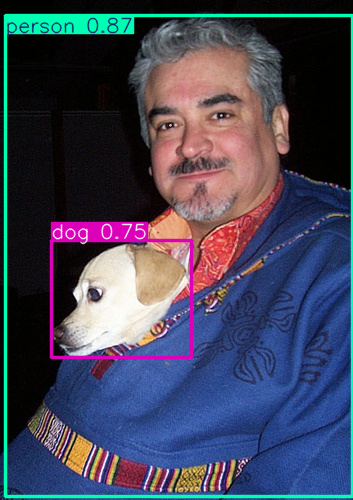

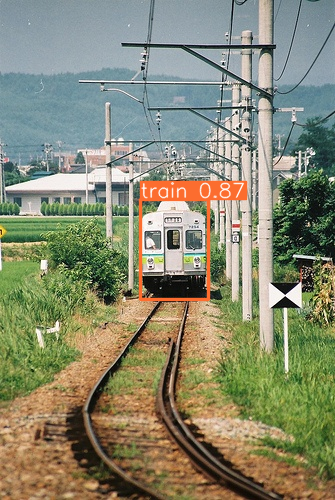

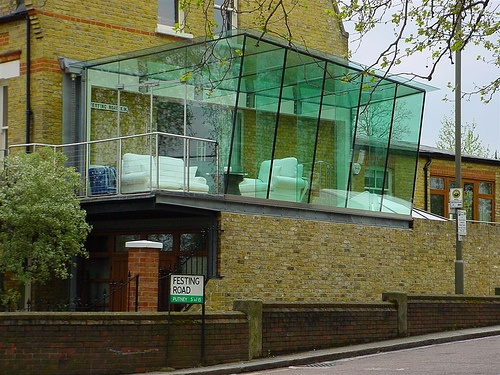

In [40]:

from ultralytics import YOLO
from IPython.display import display
from PIL import Image
from pathlib import Path

# Load the trained 5-epoch model
model_path = Path(
    "/kaggle/working/pascalvision/runs/baseline_5_epochs_kaggle/weights/best.pt"
)
model = YOLO(str(model_path))

# Find sample validation images
val_dir = Path("/kaggle/working/datasets/VOC/images/test2007")

print("Model exists:", model_path.exists())
print("Validation folder exists:", val_dir.exists())

image_paths = [
    val_dir / "000001.jpg",
    val_dir / "000002.jpg",
    val_dir / "000003.jpg",
]
image_paths = [p for p in image_paths if p.exists()]

print("Images found:", len(image_paths))

# Run object detection and display bounding boxes
if image_paths:
    results = model.predict(
        source=[str(p) for p in image_paths],
        conf=0.25,
        device=0,
        save=False
    )

    for result in results:
        display(Image.fromarray(result.plot()[:, :, ::-1]))
else:
    print("No sample images found. Check the image folder.")


In [41]:
from ultralytics.data.utils import check_det_dataset

data_info = check_det_dataset("VOC.yaml")

print("Dataset root:", data_info.get("path"))
print("Training data:", data_info.get("train"))
print("Validation data:", data_info.get("val"))
print("Classes:", len(data_info.get("names", {})))


Dataset root: /kaggle/working/datasets/VOC
Training data: ['/kaggle/working/datasets/VOC/images/train2007', '/kaggle/working/datasets/VOC/images/train2012']
Validation data: /kaggle/working/datasets/VOC/images/test2007
Classes: 20


In [42]:
from pathlib import Path

val_dir = Path("/kaggle/working/datasets/VOC/images/test2007")

image_paths = sorted([
    *val_dir.glob("*.jpg"),
    *val_dir.glob("*.jpeg"),
    *val_dir.glob("*.png")
])

print("Validation images found:", len(image_paths))
print("Example image paths:")
for path in image_paths[:5]:
    print(path)

Validation images found: 4952
Example image paths:
/kaggle/working/datasets/VOC/images/test2007/000001.jpg
/kaggle/working/datasets/VOC/images/test2007/000002.jpg
/kaggle/working/datasets/VOC/images/test2007/000003.jpg
/kaggle/working/datasets/VOC/images/test2007/000004.jpg
/kaggle/working/datasets/VOC/images/test2007/000006.jpg


Images found: 3

0: 640x640 1 dog, 1 person, 5.7ms
1: 640x640 1 train, 5.7ms
2: 640x640 (no detections), 5.7ms
Speed: 1.6ms preprocess, 5.7ms inference, 0.8ms postprocess per image at shape (1, 3, 640, 640)


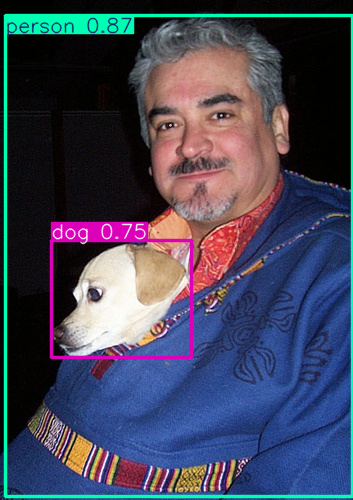

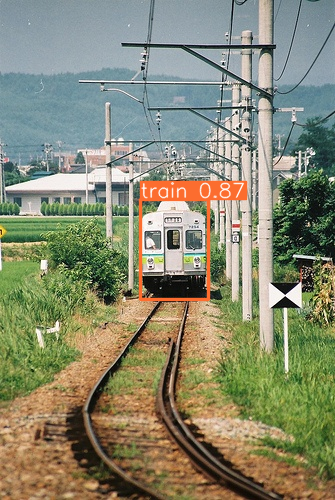

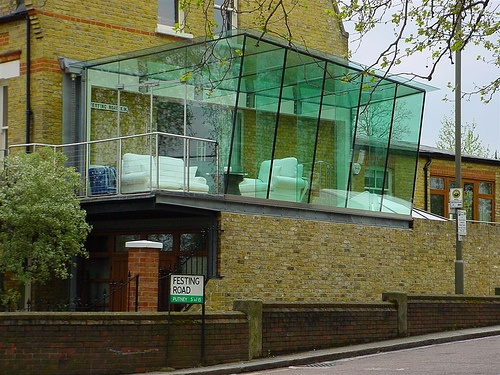

In [43]:
from ultralytics import YOLO
from IPython.display import display
from PIL import Image
from pathlib import Path

model_path = Path(
    "/kaggle/working/pascalvision/runs/"
    "baseline_5_epochs_kaggle/weights/best.pt"
)
model = YOLO(str(model_path))

image_paths = [
    Path("/kaggle/working/datasets/VOC/images/test2007/000001.jpg"),
    Path("/kaggle/working/datasets/VOC/images/test2007/000002.jpg"),
    Path("/kaggle/working/datasets/VOC/images/test2007/000003.jpg")
]

image_paths = [p for p in image_paths if p.exists()]
print("Images found:", len(image_paths))

results = model.predict(
    source=[str(p) for p in image_paths],
    conf=0.25,
    device=0,
    save=False
)

for result in results:
    display(Image.fromarray(result.plot()[:, :, ::-1]))

In [44]:
from pathlib import Path

image_name = "000003"
label_path = Path(
    f"/kaggle/working/datasets/VOC/labels/test2007/{image_name}.txt"
)

print("Label file exists:", label_path.exists())

if label_path.exists():
    labels = label_path.read_text().strip()

    if labels:
        for line in labels.splitlines():
            class_id = int(line.split()[0])
            print(f"Class: {model.names[class_id]} | Label: {line}")
    else:
        print("The label file is empty.")
else:
    print("Label file not found at this path.")

Label file exists: True
Class: sofa | Label: 17 0.336 0.46399999999999997 0.184 0.10666666666666666
Class: chair | Label: 8 0.544 0.47866666666666663 0.136 0.13066666666666665


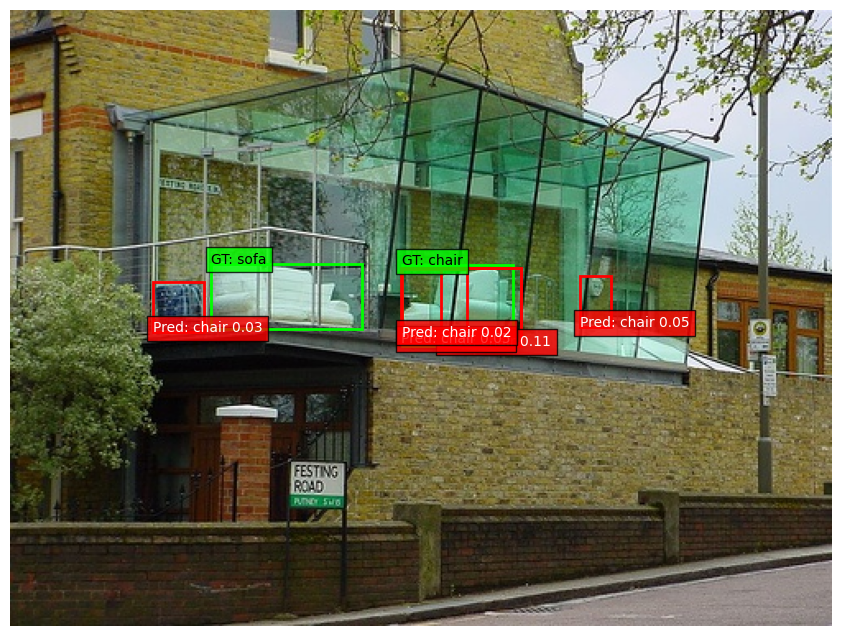

In [45]:
from PIL import Image
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.patches as patches

image_path = Path(
    "/kaggle/working/datasets/VOC/images/test2007/000003.jpg"
)
label_path = Path(
    "/kaggle/working/datasets/VOC/labels/test2007/000003.txt"
)

assert image_path.exists(), f"Image not found: {image_path}"
assert label_path.exists(), f"Labels not found: {label_path}"

image = Image.open(image_path).convert("RGB")
width, height = image.size

# Use the already-loaded model from the earlier cell
result = model.predict(
    str(image_path), conf=0.01, device=0, verbose=False
)[0]

fig, ax = plt.subplots(figsize=(12, 8))
ax.imshow(image)

# Ground-truth boxes: green
for line in label_path.read_text().strip().splitlines():
    if not line.strip():
        continue

    class_id, xc, yc, bw, bh = map(float, line.split())
    x1 = (xc - bw / 2) * width
    y1 = (yc - bh / 2) * height

    ax.add_patch(patches.Rectangle(
        (x1, y1), bw * width, bh * height,
        linewidth=2, edgecolor="lime", facecolor="none"
    ))
    ax.text(x1, y1, f"GT: {model.names[int(class_id)]}",
            color="black", bbox=dict(facecolor="lime", alpha=0.8))

# Predictions: red
for box in result.boxes:
    x1, y1, x2, y2 = box.xyxy[0].tolist()
    class_id = int(box.cls[0])
    confidence = float(box.conf[0])

    ax.add_patch(patches.Rectangle(
        (x1, y1), x2 - x1, y2 - y1,
        linewidth=2, edgecolor="red", facecolor="none"
    ))
    ax.text(x1, y2, f"Pred: {model.names[class_id]} {confidence:.2f}",
            color="white", bbox=dict(facecolor="red", alpha=0.8))

ax.axis("off")
plt.show()

In [46]:
from ultralytics import YOLO

model2 = YOLO("yolo26n.pt")

results2 = model2.train(
    data="VOC.yaml",
    epochs=10,
    imgsz=640,
    batch=16,
    device=0,
    workers=2,
    project="/kaggle/working/pascalvision/runs",
    name="experiment_10_epochs_kaggle",
    exist_ok=True
)

Ultralytics 8.4.192 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=VOC.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=experiment_10_epochs_kaggle, nbs=64, nms=None, opset=None, optimize=False, optimi

KeyboardInterrupt: 

In [47]:
from ultralytics.data.utils import check_det_dataset

data_info = check_det_dataset("VOC.yaml")

print("Dataset:", data_info.get("path"))
print("Training images:", data_info.get("train"))
print("Validation images:", data_info.get("val"))
print("Number of classes:", data_info.get("nc"))
print("Class names:", data_info.get("names"))

Dataset: /kaggle/working/datasets/VOC
Training images: ['/kaggle/working/datasets/VOC/images/train2007', '/kaggle/working/datasets/VOC/images/train2012']
Validation images: /kaggle/working/datasets/VOC/images/test2007
Number of classes: 20
Class names: {0: 'aeroplane', 1: 'bicycle', 2: 'bird', 3: 'boat', 4: 'bottle', 5: 'bus', 6: 'car', 7: 'cat', 8: 'chair', 9: 'cow', 10: 'diningtable', 11: 'dog', 12: 'horse', 13: 'motorbike', 14: 'person', 15: 'pottedplant', 16: 'sheep', 17: 'sofa', 18: 'train', 19: 'tvmonitor'}


In [48]:
from pathlib import Path

run_dir = Path(
    "/kaggle/working/pascalvision/runs/"
    "experiment_10_epochs_kaggle"
)

print("Run folder exists:", run_dir.exists())

for name in ["best.pt", "last.pt", "results.csv"]:
    matches = list(run_dir.rglob(name))
    print(f"\n{name}:")
    for path in matches:
        print(path, f"({path.stat().st_size / 1e6:.1f} MB)")

Run folder exists: True

best.pt:
/kaggle/working/pascalvision/runs/experiment_10_epochs_kaggle/weights/best.pt (5.4 MB)

last.pt:
/kaggle/working/pascalvision/runs/experiment_10_epochs_kaggle/weights/last.pt (5.4 MB)

results.csv:


In [49]:
from ultralytics import YOLO

best_path = str(
    run_dir / "weights" / "best.pt"
)

model = YOLO(best_path)
metrics = model.val(data="VOC.yaml", device=0)

print("\nFINAL VALIDATION METRICS")
print(f"Precision: {metrics.box.mp:.4f}")
print(f"Recall:    {metrics.box.mr:.4f}")
print(f"mAP50:     {metrics.box.map50:.4f}")
print(f"mAP50-95:  {metrics.box.map:.4f}")

Ultralytics 8.4.192 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO26n summary (fused): 121 layers, 2,394,352 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1964.3±729.1 MB/s, size: 114.8 KB)
val: Scanning /kaggle/working/datasets/VOC/labels/test2007.cache... 4952 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 4952/4952 989.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 36% ━━━━──────── 112/310 6.6it/s 12.3s<30.1s


KeyboardInterrupt: 

Image: 000001.jpg
Results saved to /kaggle/working/pascalvision/experiments/confidence_0.15

Threshold: 0.15
Detections: 2
Objects: person (0.92), dog (0.73)


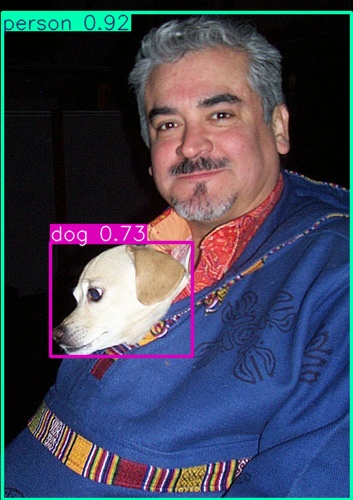

Results saved to /kaggle/working/pascalvision/experiments/confidence_0.25

Threshold: 0.25
Detections: 2
Objects: person (0.92), dog (0.73)


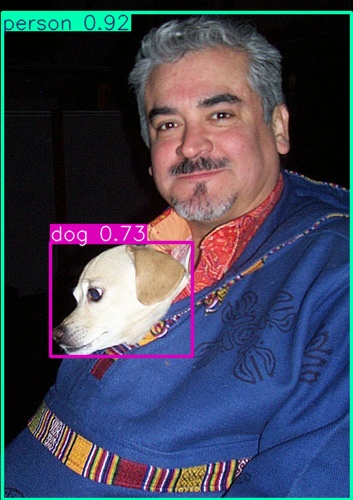

Results saved to /kaggle/working/pascalvision/experiments/confidence_0.5

Threshold: 0.50
Detections: 2
Objects: person (0.92), dog (0.73)


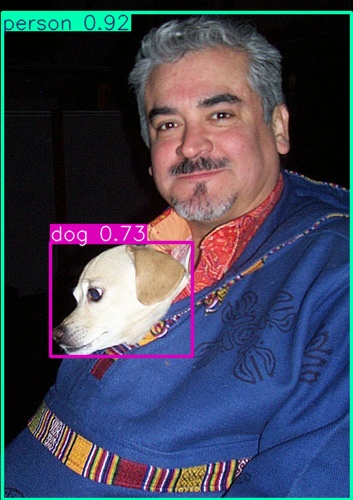

In [1]:
from ultralytics import YOLO
from pathlib import Path
from IPython.display import display, Image

# Load your trained model
weights = (
    "/kaggle/working/pascalvision/runs/"
    "experiment_10_epochs_kaggle/weights/best.pt"
)
model = YOLO(weights)

# Find a real image in the VOC test set
image_dir = Path("/kaggle/working/datasets/VOC/images/test2007")
image_path = image_dir / "000001.jpg"

# Fall back to the first available image if needed
if not image_path.exists():
    image_path = sorted(image_dir.glob("*.jpg"))[0]

print("Image:", image_path.name)

# Run the same image with three thresholds
output_dir = Path("/kaggle/working/pascalvision/experiments")
results_summary = []

for conf in [0.15, 0.25, 0.50]:
    result = model.predict(
        source=str(image_path),
        conf=conf,
        save=True,
        project=str(output_dir),
        name=f"confidence_{conf}",
        exist_ok=True,
        verbose=False
    )[0]

    count = len(result.boxes)
    classes = [
        f"{model.names[int(c)]} ({float(s):.2f})"
        for c, s in zip(result.boxes.cls, result.boxes.conf)
    ]

    results_summary.append((conf, count, classes))

    print(f"\nThreshold: {conf:.2f}")
    print(f"Detections: {count}")
    print("Objects:", ", ".join(classes) if classes else "None detected")

    saved_image = output_dir / f"confidence_{conf}" / image_path.name
    if saved_image.exists():
        display(Image(filename=str(saved_image), width=600))

In [2]:
from ultralytics import YOLO

weights = (
    "/kaggle/working/pascalvision/runs/"
    "experiment_10_epochs_kaggle/weights/best.pt"
)

model = YOLO(weights)

metrics = model.val(
    data="VOC.yaml",
    device=0,
    plots=True
)

print("\nPer-class mAP50-95:")
for i, name in model.names.items():
    print(f"{name}: {metrics.box.maps[i]:.3f}")

Ultralytics 8.4.192 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO26n summary (fused): 121 layers, 2,394,352 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1969.5±651.6 MB/s, size: 82.2 KB)
val: Scanning /kaggle/working/datasets/VOC/labels/test2007.cache... 4952 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 4952/4952 741.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 5% ╸─────────── 18/310 6.6it/s 2.8s<44.2s


KeyboardInterrupt: 

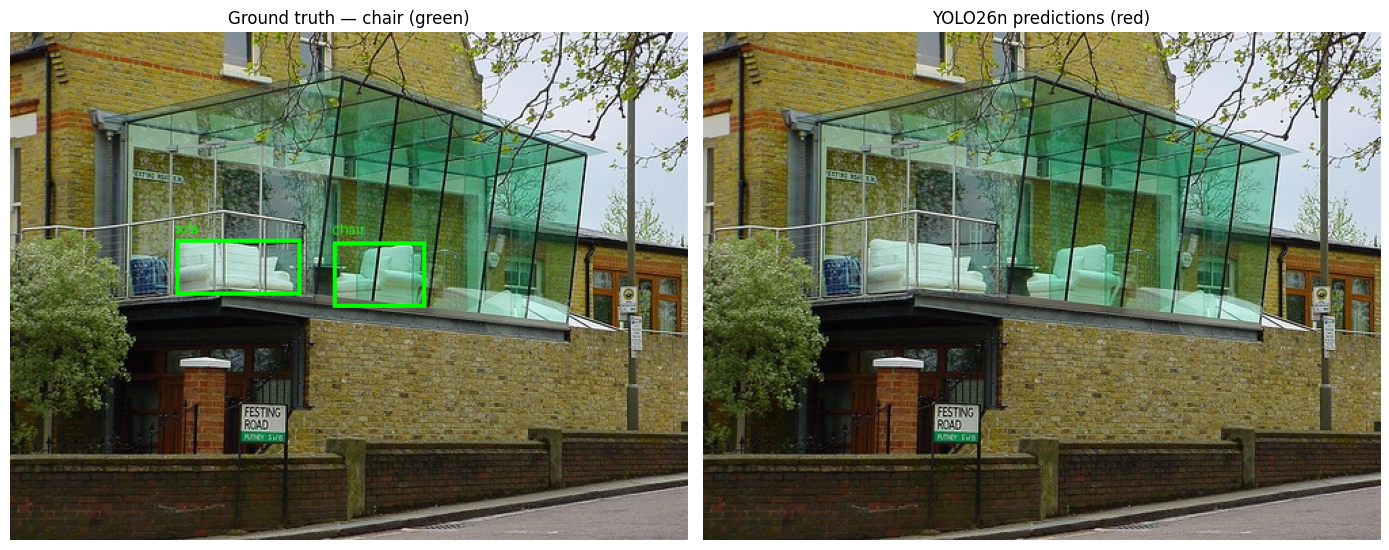

Image: 000003.jpg


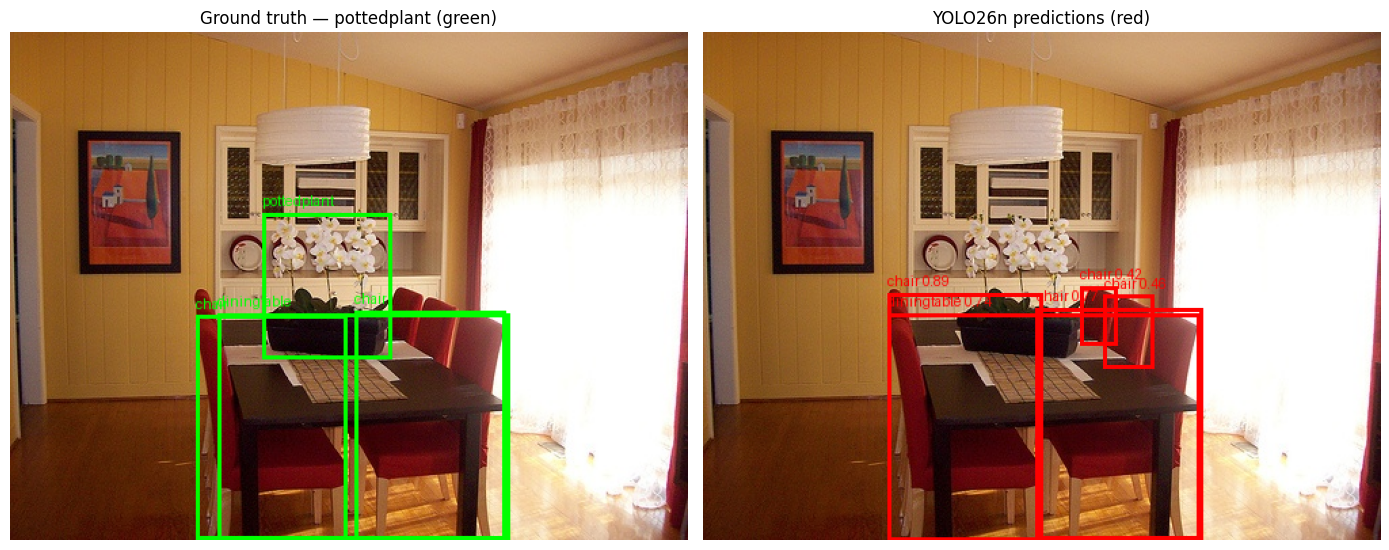

Image: 000006.jpg


In [4]:
from pathlib import Path
from ultralytics import YOLO
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

model = YOLO(
    "/kaggle/working/pascalvision/runs/"
    "experiment_10_epochs_kaggle/weights/best.pt"
)

image_dir = Path("/kaggle/working/datasets/VOC/images/test2007")
label_dir = Path("/kaggle/working/datasets/VOC/labels/test2007")

# Pascal VOC class IDs: chair=8, pottedplant=15
target_classes = {8: "chair", 15: "pottedplant"}
examples = {}

# Find one annotated image for each class
for label_path in sorted(label_dir.glob("*.txt")):
    lines = label_path.read_text().strip().splitlines()
    classes_here = set()

    for line in lines:
        parts = line.split()
        if len(parts) == 5:
            classes_here.add(int(float(parts[0])))

    for class_id, class_name in target_classes.items():
        if class_id in classes_here and class_name not in examples:
            for ext in [".jpg", ".jpeg", ".png"]:
                candidate = image_dir / (label_path.stem + ext)
                if candidate.exists():
                    examples[class_name] = (candidate, label_path)
                    break

    if len(examples) == 2:
        break

for class_name, (image_path, label_path) in examples.items():
    image = Image.open(image_path).convert("RGB")
    w, h = image.size

    # Ground truth: green boxes
    gt_image = image.copy()
    draw = ImageDraw.Draw(gt_image)

    for line in label_path.read_text().strip().splitlines():
        parts = line.split()
        if len(parts) != 5:
            continue

        cls, xc, yc, bw, bh = map(float, parts)
        if int(cls) != target_classes_for_id if False else False:
            pass

        x1 = (xc - bw / 2) * w
        y1 = (yc - bh / 2) * h
        x2 = (xc + bw / 2) * w
        y2 = (yc + bh / 2) * h
        draw.rectangle([x1, y1, x2, y2], outline="lime", width=3)
        draw.text((x1, max(0, y1 - 15)), model.names[int(cls)], fill="lime")

    # Predictions: red boxes
    result = model.predict(
        source=str(image_path), conf=0.25, verbose=False
    )[0]
    pred_image = image.copy()
    draw = ImageDraw.Draw(pred_image)

    for box in result.boxes:
        x1, y1, x2, y2 = map(float, box.xyxy[0].tolist())
        cls = int(box.cls[0])
        score = float(box.conf[0])
        draw.rectangle([x1, y1, x2, y2], outline="red", width=3)
        draw.text((x1, max(0, y1 - 15)),
                  f"{model.names[cls]} {score:.2f}", fill="red")

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    axes[0].imshow(gt_image)
    axes[0].set_title(f"Ground truth — {class_name} (green)")
    axes[1].imshow(pred_image)
    axes[1].set_title("YOLO26n predictions (red)")
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

    print("Image:", image_path.name)

/kaggle/working/pascalvision/runs/baseline_5_epochs_kaggle/weights/best.pt -> True
/kaggle/working/pascalvision/runs/experiment_10_epochs_kaggle/weights/best.pt -> True
/kaggle/working/datasets/VOC/images/test2007/000003.jpg -> True


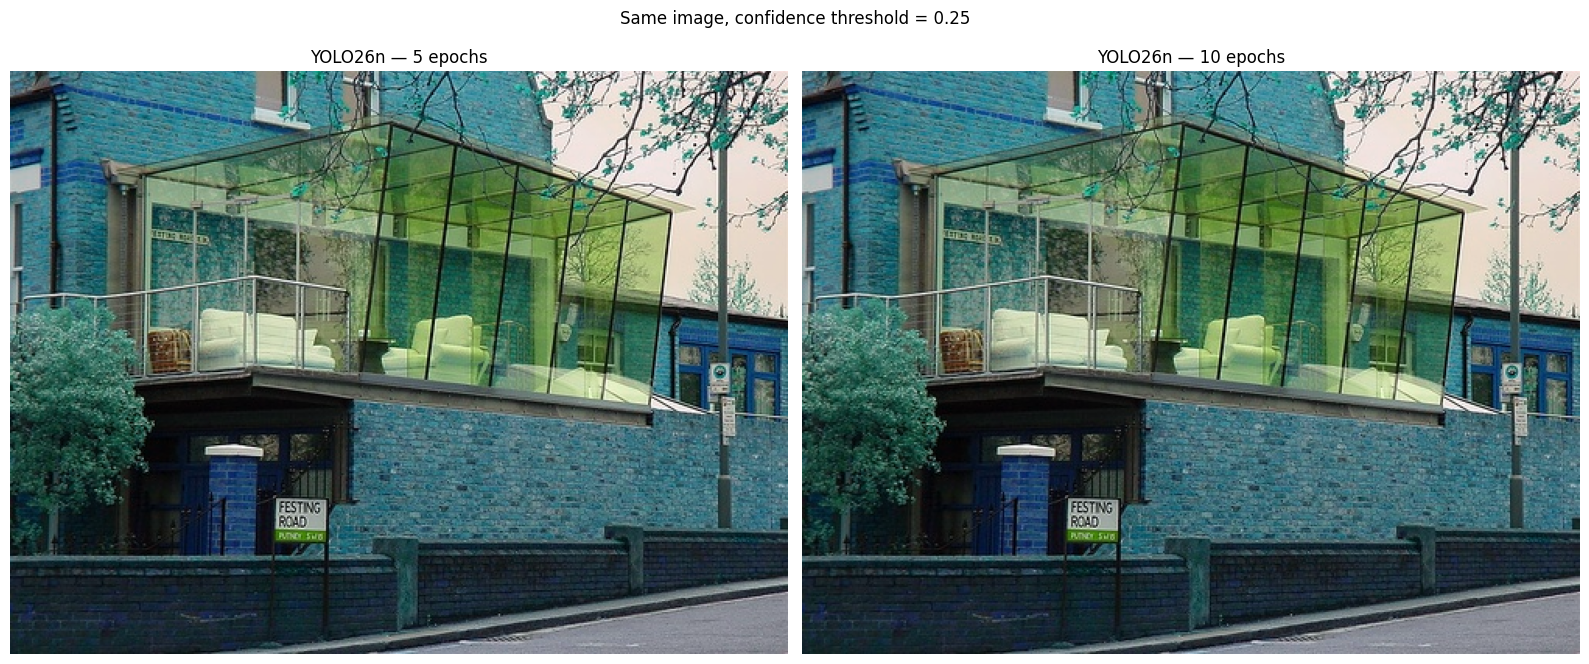

5 epochs — detections: 0
10 epochs — detections: 0


In [5]:
from ultralytics import YOLO
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

# Update this path if your 5-epoch checkpoint is stored elsewhere.
weights_5 = (
    "/kaggle/working/pascalvision/runs/"
    "baseline_5_epochs_kaggle/weights/best.pt"
)

weights_10 = (
    "/kaggle/working/pascalvision/runs/"
    "experiment_10_epochs_kaggle/weights/best.pt"
)

image_dir = Path(
    "/kaggle/working/datasets/VOC/images/test2007"
)
image_path = image_dir / "000003.jpg"

# Check paths before loading
for p in [weights_5, weights_10, str(image_path)]:
    print(p, "->", Path(p).exists())

assert Path(weights_5).exists(), (
    "5-epoch checkpoint not found. Locate the .pt file first."
)
assert Path(weights_10).exists(), (
    "10-epoch checkpoint not found."
)
assert image_path.exists(), (
    "Example image not found."
)

model_5 = YOLO(weights_5)
model_10 = YOLO(weights_10)

conf_threshold = 0.25

result_5 = model_5.predict(
    str(image_path), conf=conf_threshold, verbose=False
)[0]

result_10 = model_10.predict(
    str(image_path), conf=conf_threshold, verbose=False
)[0]

image = Image.open(image_path).convert("RGB")

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

axes[0].imshow(result_5.plot())
axes[0].set_title("YOLO26n — 5 epochs")
axes[0].axis("off")

axes[1].imshow(result_10.plot())
axes[1].set_title("YOLO26n — 10 epochs")
axes[1].axis("off")

plt.suptitle(
    f"Same image, confidence threshold = {conf_threshold}"
)
plt.tight_layout()
plt.show()

print("5 epochs — detections:", len(result_5.boxes))
print("10 epochs — detections:", len(result_10.boxes))

In [14]:
from ultralytics import YOLO

baseline = YOLO("yolo26n.pt")

baseline_results = baseline.train(
    data="VOC.yaml",
    epochs=5,
    imgsz=640,
    batch=16,
    device=0,
    workers=2,
    project="/kaggle/working/pascalvision/runs",
    name="baseline_5_epochs_kaggle",
    exist_ok=True
)

print("5-epoch training finished.")
print("Checkpoint should be saved at:")
print(
    "/kaggle/working/pascalvision/runs/"
    "baseline_5_epochs_kaggle/weights/best.pt"
)

Ultralytics 8.4.192 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=VOC.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=baseline_5_epochs_kaggle, nbs=64, nms=None, opset=None, optimize=False, optimizer=

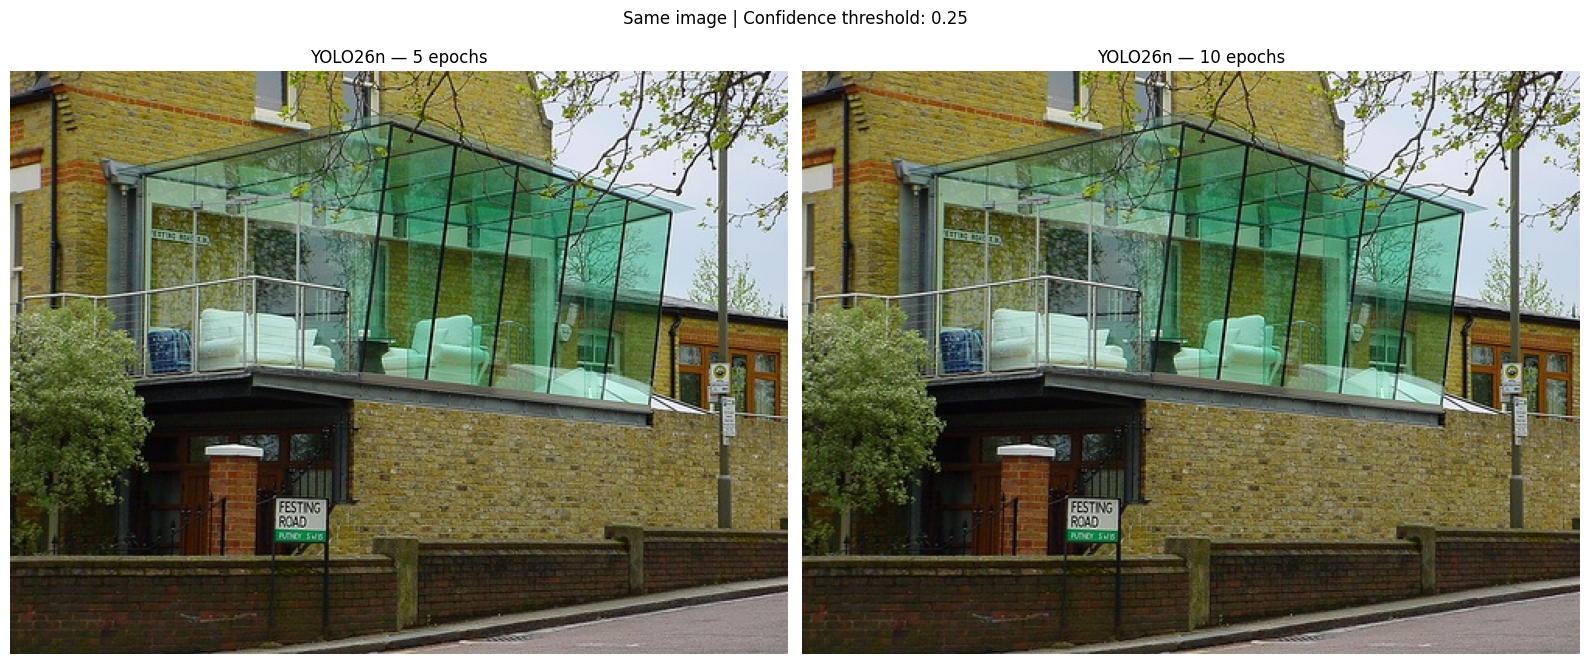

5-epoch detections: 0
10-epoch detections: 0


In [15]:
from ultralytics import YOLO
from pathlib import Path
import matplotlib.pyplot as plt

# Load both saved checkpoints
model_5 = YOLO(
    "/kaggle/working/pascalvision/runs/"
    "baseline_5_epochs_kaggle/weights/best.pt"
)

model_10 = YOLO(
    "/kaggle/working/pascalvision/runs/"
    "experiment_10_epochs_kaggle/weights/best.pt"
)

# Use the same image for both models
image_path = Path(
    "/kaggle/working/datasets/VOC/images/test2007/000003.jpg"
)
assert image_path.exists(), f"Image not found: {image_path}"

conf = 0.25

result_5 = model_5.predict(
    source=str(image_path), conf=conf, verbose=False
)[0]

result_10 = model_10.predict(
    source=str(image_path), conf=conf, verbose=False
)[0]

# Plot both predictions side by side
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

axes[0].imshow(result_5.plot()[:, :, ::-1])
axes[0].set_title("YOLO26n — 5 epochs")
axes[0].axis("off")

axes[1].imshow(result_10.plot()[:, :, ::-1])
axes[1].set_title("YOLO26n — 10 epochs")
axes[1].axis("off")

plt.suptitle(f"Same image | Confidence threshold: {conf}")
plt.tight_layout()
plt.show()

print("5-epoch detections:", len(result_5.boxes))
print("10-epoch detections:", len(result_10.boxes))

In [16]:
import pandas as pd

comparison = pd.DataFrame({
    "Metric": ["Precision", "Recall", "mAP50", "mAP50-95"],
    "5 epochs": [0.828, 0.781, 0.862, 0.665],
    "10 epochs": [0.825, 0.790, 0.861, 0.667],
})

comparison["Change (percentage points)"] = (
    comparison["10 epochs"] - comparison["5 epochs"]
) * 100

display(comparison.round(3))

comparison.to_csv(
    "/kaggle/working/pascalvision_model_comparison.csv",
    index=False
)

print("Saved metrics comparison CSV.")

,Metric,5 epochs,10 epochs,Change (percentage points)
0,Precision,0.828,0.825,-0.3
1,Recall,0.781,0.790,0.9
2,mAP50,0.862,0.861,-0.1
3,mAP50-95,0.665,0.667,0.2


Saved metrics comparison CSV.


In [33]:

from ultralytics import YOLO

weights = (
    "/kaggle/working/pascalvision/runs/"
    "experiment_10_epochs_kaggle/weights/best.pt"
)

model = YOLO(weights)

metrics = model.val(
    data="/kaggle/working/VOC.yaml",
    device=0,
    plots=True
)

print("\n10-EPOCH MODEL — VALIDATION METRICS")
print(f"Precision: {metrics.box.mp:.4f}")
print(f"Recall:    {metrics.box.mr:.4f}")
print(f"mAP50:     {metrics.box.map50:.4f}")
print(f"mAP50-95:  {metrics.box.map:.4f}")


Ultralytics 8.4.192 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO26n summary (fused): 121 layers, 2,394,352 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2418.9±398.8 MB/s, size: 114.8 KB)
val: Scanning /kaggle/working/datasets/VOC/labels/test2007.cache... 4952 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 4952/4952 903.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 310/310 9.6it/s 32.2s<0.1s
                   all       4952      12032      0.825       0.79      0.861      0.667
             aeroplane        204        285      0.899      0.884      0.931      0.721
               bicycle        239        337      0.903      0.805      0.925      0.716
                  bird        282        459      0.825      0.758      0.849      0.619
                  boat        172        263      0.771      0.653      0.753      0.524
                b

In [34]:

from ultralytics import YOLO

baseline_path = (
    "/kaggle/working/pascalvision/runs/"
    "baseline_5_epochs_kaggle/weights/best.pt"
)

baseline = YOLO(baseline_path)

baseline_metrics = baseline.val(
    data="/kaggle/working/VOC.yaml",
    device=0,
    plots=False
)

print("\n5-EPOCH BASELINE — VALIDATION METRICS")
print(f"Precision: {baseline_metrics.box.mp:.4f}")
print(f"Recall:    {baseline_metrics.box.mr:.4f}")
print(f"mAP50:     {baseline_metrics.box.map50:.4f}")
print(f"mAP50-95:  {baseline_metrics.box.map:.4f}")


Ultralytics 8.4.192 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO26n summary (fused): 121 layers, 2,394,352 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1765.5±615.9 MB/s, size: 86.6 KB)
val: Scanning /kaggle/working/datasets/VOC/labels/test2007.cache... 4952 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 4952/4952 798.9Mit/s 0.0s


Traceback (most recent call last):
  File "/usr/lib/python3.13/multiprocessing/queues.py", line 257, in _feed
    reader_close()
    ~~~~~~~~~~~~^^
  File "/usr/lib/python3.13/multiprocessing/connection.py", line 183, in close
    self._close()
    ~~~~~~~~~~~^^
  File "/usr/lib/python3.13/multiprocessing/connection.py", line 382, in _close
    _close(self._handle)
    ~~~~~~^^^^^^^^^^^^^^
OSError: [Errno 9] Bad file descriptor


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 310/310 11.2it/s 27.6s0.1ss
                   all       4952      12032      0.831      0.778      0.862      0.665
             aeroplane        204        285      0.896      0.863      0.916      0.703
               bicycle        239        337      0.921      0.796      0.923      0.717
                  bird        282        459      0.847      0.738      0.867      0.623
                  boat        172        263      0.818      0.649       0.78      0.535
                bottle        212        469      0.808      0.718      0.812      0.574
                   bus        174        213      0.882      0.845      0.927      0.819
                   car        721       1201      0.876      0.866      0.934      0.759
                   cat        322        358      0.876      0.838      0.914      0.771
                 chair        417        756      0.727      0.

In [9]:

import pandas as pd
from pathlib import Path

comparison = pd.DataFrame({
    "Metric": ["Precision", "Recall", "mAP50", "mAP50-95"],
    "5 epochs": [0.8306, 0.7784, 0.8620, 0.6649],
    "10 epochs": [0.8251, 0.7898, 0.8605, 0.6672],
})

comparison["Change (percentage points)"] = (
    comparison["10 epochs"] - comparison["5 epochs"]
) * 100

display(comparison.round(4))

output_dir = Path("/kaggle/working/pascalvision")
output_dir.mkdir(parents=True, exist_ok=True)

csv_path = output_dir / "model_comparison.csv"
comparison.to_csv(csv_path, index=False)

print("Comparison saved to:", csv_path)


,Metric,5 epochs,10 epochs,Change (percentage points)
0,Precision,0.8306,0.8251,-0.55
1,Recall,0.7784,0.7898,1.14
2,mAP50,0.8620,0.8605,-0.15
3,mAP50-95,0.6649,0.6672,0.23


Comparison saved to: /kaggle/working/pascalvision/model_comparison.csv
